In [1]:
# Bibliotecas

import geemap
import numpy as np
import geopandas as gpd
import geobr
import ee
import json


In [2]:
# Autenticação

ee.Authenticate()
ee.Initialize(project='ee-wanderamufv')

In [13]:
# Lendo o vetor do DF

DF = geobr.read_state(code_state='DF', year=2018)

DF

,code_state,name_state,abbrev_state,code_region,name_region,year,geometry
0,53.0,Distrito Federal,DF,5.0,Centro-Oeste,2018.0,"POLYGON ((-48.27781 -16.0496, -47.3085 -16.049..."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

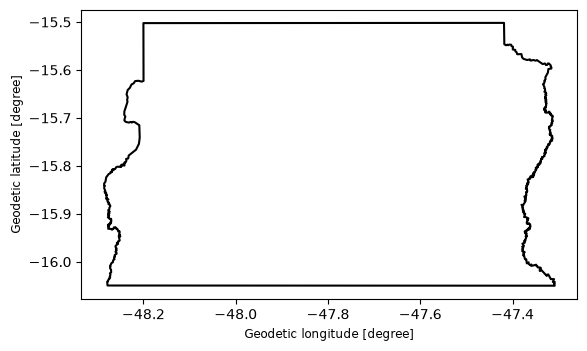

In [36]:
DF.boundary.plot(color='k')

In [37]:
# Covertendo as coordenadas de geodataframe para json

df_json = DF.to_json()

In [38]:
# Carregando o arquivo json
df_json_coords = json.loads(df_json)
type(df_json_coords)

dict

In [39]:
print(df_json_coords)

{'type': 'FeatureCollection', 'features': [{'id': '0', 'type': 'Feature', 'properties': {'code_state': 53.0, 'name_state': 'Distrito Federal', 'abbrev_state': 'DF', 'code_region': 5.0, 'name_region': 'Centro-Oeste', 'year': 2018.0}, 'geometry': {'type': 'Polygon', 'coordinates': [[[-48.277811199999995, -16.049597799999997], [-47.3085041, -16.049971399999997], [-47.30997489999999, -16.048485999999997], [-47.308494499999995, -16.04567429999999], [-47.31018299999999, -16.044519599999994], [-47.308500300000006, -16.042092], [-47.3126749, -16.0421107], [-47.31000619999999, -16.0362735], [-47.316932900000005, -16.036191599999995], [-47.32246879999999, -16.026514], [-47.32540609999999, -16.027100699999995], [-47.3256782, -16.029618699999997], [-47.337363599999996, -16.0174428], [-47.3406074, -16.01943619999999], [-47.341057, -16.018016199999995], [-47.33969449999999, -16.016873299999997], [-47.341162399999995, -16.0153387], [-47.33874129999999, -16.0150364], [-47.3384231, -16.013449800000007]

In [40]:
# Selecionando coordenadas
df_coord = df_json_coords['features']

In [43]:
# Convertendo as coordenadas para o tipo FeatureCollection do Earth Engine
aoi = ee.FeatureCollection(df_coord)

In [45]:
# Chamando a coleção

collection = ee.ImageCollection('LANDSAT/LE07/C02/T1_L2')\
    .filterDate('2001-07-20', '2001-07-21')\
    .filterBounds(aoi)\


print(f'Número de cenas: {collection.size().getInfo()}')

Número de cenas: 1


In [47]:
# Visualizando a cena utilizando o geemap

mapa = geemap.Map()
mapa.centerObject(aoi, zoom=7)
mapa.add_basemap('SATELLITE')
mapa.addLayer(collection.select('SR_B3', 'SR_B4', 'SR_B2'), {'gamma': 2})
mapa.addLayerControl()


mapa

Map(center=[-15.781437324803912, -47.796830098960555], controls=(WidgetControl(options=['position', 'transpare…